## Detection and Linking Results

In this notebook, we walk through the steps used in White et al. 2026 to determine the range of NGA magnitudes that Sorcha and heliolinx are capable of detecting and linking, respectively. 

### Imports and initializing our file locations

First, we must import the necessary modules and specify the locations of files needed to run Sorcha and heliolinx. The filepaths should be changed by the user so that they match the path to each file on your machine. 

In [1]:
## import statements 

import os 
import sys
import glob

import numpy as np
import pylab as plt
import pandas as pd

import random
import subprocess
import sorcha
from astroquery.jplhorizons import Horizons
from astroquery.jplsbdb import SBDB

## location of kep2cart.py program
k2c_path = '/home/ellie/research/lsst/lsst_seti/nongrav/sorcha_ng'

## import the kep2cart module
kep_dir = os.path.abspath(k2c_path)
sys.path.insert(0, kep_dir)

from kep2cart import kep2cart as k2c

In [78]:
## define our filepaths and filename stems

## filepath for sorcha input and output files
sfpath = "/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/" #obj/"

## filename stems for the orbit files and other files
fname_orb = "fantastic_orb" #2000_obj_orb"
fname_stem = "fantastic" #2000_obj"

## object ID
obj_id = "fantastic" #2000_obj"

## location of Sorcha config file
config_fpath = "Rubin_full_footprint.ini"

## location of pointing database file for Sorcha
pointing_db_path = "/home/ellie/src/sorcha/sorcha/demo/baseline_v2.0_1yr.db"

## location of Earth location file for HelioLinC
earth1day_path = '/home/ellie/research/lsst/heliolinc_files/Earth1day2020s_02a.csv'

## location of ObsCodes file for HelioLinC
obscodes_path = '/home/ellie/research/lsst/heliolinc_files/ObsCodes.html'

## location of colformat file for HelioLinC
colformat_path = '/home/ellie/research/lsst/heliolinc_files/colformat.txt'

## location of hypothesis file for HelioLinC
hypo_path = '/home/ellie/research/lsst/sorcha_output/127005pratchett_new/hihyp00b_mb.txt'

### Create Sorcha input files for the 2000-object Main Belt Asteroid sample

Now, read in a file containing information about a large subset of objects (500,010 objects) in the Minor Planet Center (MPC) MPCORB database (note that this file contains information about all types of objects in the MPC, not just Main Belt Asteroids):

In [3]:
## read in the MPC file we created awhile back:
df = pd.read_csv('/home/ellie/research/lsst/mpcorb_csvs/mpcorb_extended_complete_vel_2sept.csv')

/tmp/ipykernel_8515/1310468857.py:2: DtypeWarning: Columns (15) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/home/ellie/research/lsst/mpcorb_csvs/mpcorb_extended_complete_vel_2sept.csv')


Filter the objects in the MPC database we just loaded in, in order to retrieve only the Main Belt Asteroids (MBAs):

In [4]:
main_belts = df.loc[df['Orbit_type'] == 'MBA']
main_belts = main_belts.reset_index(drop=True)
print("Number of MBAs: {}".format(len(main_belts)))

Number of MBAs: 472906


Select 2000 MBAs at random from our filtered dataset; define the random seed so that we always choose the same 2000 random MBAs each time we run the code:

In [5]:
min_n = 0
max_n = len(main_belts)-1
length = 2000
random.seed(42)

indices = [random.randint(min_n, max_n) for n in range(length)]
mba_sample = main_belts.loc[indices]
mba_sample = mba_sample.reset_index(drop=True)

Retrieve the orbital elements and magnitude information about each of the 2000 objects from JPL Horizons, then create a Sorcha-compatible Keplerian Orbits file containing information about each of the objects in our sample:

In [7]:
## use MJD 62018.00 as our start date for querying the osculating elements

start_mjd = 62018.00
start_jd = start_mjd+2400000.5

ids = []
a = []
e = []
inc = []
node = []
arg_peri = []
ma = []

H = []
G = []

for i in range(len(mba_sample)):
    obj = Horizons(id=mba_sample['Principle_desig'][i], location='500@10',epochs=start_jd)
    el = obj.elements()
    #print(el['a'][0])

    id = el['targetname'][0].split()[0]    
    ids.append(id)
    
    a.append(float(el['a'][0]))
    e.append(float(el['e'][0]))
    inc.append(float(el['incl'][0]))
    node.append(float(el['Omega'][0]))
    arg_peri.append(float(el['w'][0]))
    ma.append(float(el['M'][0]))
    H.append(float(el['H'][0]))
    G.append(float(el['G'][0]))

    #print(f"we have processed {i+1} asteroids")

    if i%10 == 0:
        print(f"we have processed {i+1} asteroids")

df_mba = pd.DataFrame()

df_mba['ObjID'] = ids
df_mba['FORMAT'] = ['KEP']*len(mba_sample)
df_mba['a'] = a
df_mba['e'] = e
df_mba['inc'] = inc 
df_mba['node'] = node
df_mba['argPeri'] = arg_peri
df_mba['ma'] = ma
df_mba['epochMJD_TDB'] = [start_mjd]*len(mba_sample)

df_mba.to_csv(f'{fname_orb}.csv', index=False)

df_phy = pd.DataFrame()
df_phy['ObjID'] = ids
df_phy['H'] = H
df_phy['G'] = G
df_phy.to_csv(f'{fname_stem}_H_and_G.csv', index=False)

we have processed 1 asteroids
we have processed 11 asteroids
we have processed 21 asteroids
we have processed 31 asteroids
we have processed 41 asteroids
we have processed 51 asteroids
we have processed 61 asteroids
we have processed 71 asteroids
we have processed 81 asteroids
we have processed 91 asteroids
we have processed 101 asteroids
we have processed 111 asteroids
we have processed 121 asteroids
we have processed 131 asteroids
we have processed 141 asteroids
we have processed 151 asteroids
we have processed 161 asteroids
we have processed 171 asteroids
we have processed 181 asteroids
we have processed 191 asteroids
we have processed 201 asteroids
we have processed 211 asteroids
we have processed 221 asteroids
we have processed 231 asteroids
we have processed 241 asteroids
we have processed 251 asteroids
we have processed 261 asteroids
we have processed 271 asteroids
we have processed 281 asteroids
we have processed 291 asteroids
we have processed 301 asteroids
we have processed 3

Convert the Keplerian Orbit input file to a Cartesian Orbit input file for Sorcha, which we can then use to generate our Nongravitational Orbit files:

In [8]:
k2c("{0}.csv".format(fname_orb), "{0}{1}_cart.csv".format(sfpath, fname_orb))

New Cartesian orbits file /home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/fantastic_orb_cart.csv written.


Create a Nongravitational Orbit file for each NGA increment (from 10<sup>-12</sup> to 10<sup>-3</sup> au/day<sup>2</sup>), for each A<sub>i</sub> component. Note that each file contains all 2000 objects. 

In [9]:
nongravs = np.logspace(start=-12, stop=-3, num=10, base=10) 

df = pd.read_csv("{0}{1}_cart.csv".format(sfpath, fname_orb))
df['FORMAT'] = 'NONGRAV'
df['a1'] = [0.0]*len(df)
df['a2'] = [0.0]*len(df)
df['a3'] = [0.0]*len(df)
df['model'] = 'ASTEROID'
epoch = df.pop('epochMJD_TDB')
df.insert(12, 'epochMJD_TDB', epoch)

orb_files = ["{0}{1}_cart.csv".format(sfpath, fname_orb)]

for i in range(len(nongravs)):
    df1 = df.copy()
    df1['a1'] = [nongravs[i]]*len(df)
    df1_fname = "{0}{1}_ng_a1_{2}.csv".format(sfpath, fname_orb, np.log10(nongravs[i]))
    df1.to_csv(df1_fname, index=False)

    df2 = df.copy()
    df2['a2'] = [nongravs[i]]*len(df)
    df2_fname = "{0}{1}_ng_a2_{2}.csv".format(sfpath, fname_orb, np.log10(nongravs[i]))
    df2.to_csv(df2_fname, index=False)

    df3 = df.copy()
    df3['a3'] = [nongravs[i]]*len(df)
    df3_fname = "{0}{1}_ng_a3_{2}.csv".format(sfpath, fname_orb, np.log10(nongravs[i]))
    df3.to_csv(df3_fname, index=False)

    orb_files.append(df1_fname)
    orb_files.append(df2_fname)
    orb_files.append(df3_fname)  

df_orbfiles = pd.DataFrame()
df_orbfiles['orb_files'] = orb_files

Create a Physical Parameters input file for Sorcha; make the simplifying assumption that all of our asteroids are C-type.

In [10]:
df_spec_V = pd.read_csv('colors_lut_V.csv', sep='\\s+')
df_spec = pd.read_csv('spectral_type_lut.csv')
u_mag = np.array([df_spec['C'][0]]*len(df_mba))
g_mag = np.array([df_spec['C'][1]]*len(df_mba))
r_mag = np.array([df_spec['C'][2]]*len(df_mba)) 
i_mag = np.array([df_spec['C'][3]]*len(df_mba))
z_mag = np.array([df_spec['C'][4]]*len(df_mba))
y_mag = np.array([df_spec['C'][5]]*len(df_mba))

df_HG = pd.read_csv(f'{fname_stem}_H_and_G.csv')

df_phy = pd.DataFrame()
c_idx = df_spec_V[df_spec_V['spectral_type'] == 'C'].index[0]

df_phy['ObjID'] = df_mba['ObjID']
df_phy['H_r'] = df_HG['H'] - df_spec_V['V-r'][c_idx] ## note that we are setting the visual H mag as our V-mag now
df_phy['u-r'] = u_mag-r_mag
df_phy['g-r'] = g_mag-r_mag
df_phy['i-r'] = i_mag-r_mag
df_phy['z-r'] = z_mag-r_mag
df_phy['y-r'] = y_mag-r_mag
df_phy['GS'] = df_HG['G']

print(df_phy.head(5))
df_phy.to_csv("{0}{1}_phy.csv".format(sfpath, fname_stem), index=False)

    ObjID        H_r       u-r       g-r       i-r       z-r      y-r    GS
0  362629  16.443888  1.684176  0.469244 -0.116649 -0.121954 -0.12654  0.15
1   71515  14.843888  1.684176  0.469244 -0.116649 -0.121954 -0.12654  0.15
2   24186  14.813888  1.684176  0.469244 -0.116649 -0.121954 -0.12654  0.15
3  419440  16.483888  1.684176  0.469244 -0.116649 -0.121954 -0.12654  0.15
4  161190  14.783888  1.684176  0.469244 -0.116649 -0.121954 -0.12654  0.15


Before running Sorcha, create a list of output filenames to place our Sorcha output in:

In [22]:
ofnames = []

for idx in range(len(orb_files)):

    ## define the output filename stem (no extension)
    ofname = orb_files[idx].replace("_orb", "") 
    ofname = ofname.split('/')[-1]
    ofname = ofname.split('.')[:-1]
    ofname = '.'.join(ofname)

    ofnames.append(ofname)

#ofnames.sort()

print(ofnames)

df_orbfiles['of_names'] = ofnames
orbfiles_list = f'orb_files_{obj_id}.csv'
df_orbfiles.to_csv(orbfiles_list, index=False)

['fantastic_cart', 'fantastic_ng_a1_-12.0', 'fantastic_ng_a2_-12.0', 'fantastic_ng_a3_-12.0', 'fantastic_ng_a1_-11.0', 'fantastic_ng_a2_-11.0', 'fantastic_ng_a3_-11.0', 'fantastic_ng_a1_-10.0', 'fantastic_ng_a2_-10.0', 'fantastic_ng_a3_-10.0', 'fantastic_ng_a1_-9.0', 'fantastic_ng_a2_-9.0', 'fantastic_ng_a3_-9.0', 'fantastic_ng_a1_-8.0', 'fantastic_ng_a2_-8.0', 'fantastic_ng_a3_-8.0', 'fantastic_ng_a1_-7.0', 'fantastic_ng_a2_-7.0', 'fantastic_ng_a3_-7.0', 'fantastic_ng_a1_-6.0', 'fantastic_ng_a2_-6.0', 'fantastic_ng_a3_-6.0', 'fantastic_ng_a1_-5.0', 'fantastic_ng_a2_-5.0', 'fantastic_ng_a3_-5.0', 'fantastic_ng_a1_-4.0', 'fantastic_ng_a2_-4.0', 'fantastic_ng_a3_-4.0', 'fantastic_ng_a1_-3.0', 'fantastic_ng_a2_-3.0', 'fantastic_ng_a3_-3.0']


### Run Sorcha

As the title says -- we will now run Sorcha on each of the nongrav orbits files we generated in the previous step. 

In [24]:
for i in range(len(orb_files)):
    print(orb_files[i])
    print(ofnames[i])
    subprocess.run(["sorcha","run","-c", config_fpath,"-p","{0}{1}_phy.csv".format(sfpath, fname_stem),"--orbits",\
                    orb_files[i],"--pd",pointing_db_path,"-o",sfpath,"-t",sfpath+ofnames[i],\
                    "--st","{0}{1}_stats".format(sfpath,ofnames[i]), '-f'])

    print('\n{0} out of {1} ({2} %) complete'.format(i+1, len(orb_files), 100*round((i+1)/len(orb_files), 2)))

/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/fantastic_orb_cart.csv
fantastic_cart

1 out of 31 (3.0 %) complete
/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/fantastic_orb_ng_a1_-12.0.csv
fantastic_ng_a1_-12.0

2 out of 31 (6.0 %) complete
/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/fantastic_orb_ng_a2_-12.0.csv
fantastic_ng_a2_-12.0

3 out of 31 (10.0 %) complete
/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/fantastic_orb_ng_a3_-12.0.csv
fantastic_ng_a3_-12.0

4 out of 31 (13.0 %) complete
/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/fantastic_orb_ng_a1_-11.0.csv
fantastic_ng_a1_-11.0

5 out of 31 (16.0 %) complete
/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/fantastic_orb_ng_a2_-11.0.csv
fantastic_ng_a2_-11.0

6 out of 31 (19.0 %) complete
/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/fantastic_orb_

/home/ellie/src/sorcha/sorcha/src/sorcha/ephemeris/simulation_driver.py:305: RuntimeWarning: invalid value encountered in arccos
  phase_angle = np.arccos(


Error: cannot interpolate beyond timestep bounds (h=1.060013e+06).
Error: cannot interpolate beyond timestep bounds (h=inf).
Error: cannot interpolate beyond timestep bounds (h=-inf).
Error: cannot interpolate beyond timestep bounds (h=-inf).
Error: cannot interpolate beyond timestep bounds (h=inf).
Error: cannot interpolate beyond timestep bounds (h=-inf).
Error: cannot interpolate beyond timestep bounds (h=-inf).
Error: cannot interpolate beyond timestep bounds (h=inf).
Error: cannot interpolate beyond timestep bounds (h=-inf).
Error: cannot interpolate beyond timestep bounds (h=-inf).
Error: cannot interpolate beyond timestep bounds (h=inf).
Error: cannot interpolate beyond timestep bounds (h=-inf).
Error: cannot interpolate beyond timestep bounds (h=-inf).
Error: cannot interpolate beyond timestep bounds (h=inf).
Error: cannot interpolate beyond timestep bounds (h=-inf).
Error: cannot interpolate beyond timestep bounds (h=-inf).
Error: cannot interpolate beyond timestep bounds (h=i

Now, create a list of file stem names corresponding to the output files just generated by Sorcha, so we don't have to re-run Sorcha to run the following cells. 

In [13]:
ofnames = []

nga_vals = ['-12.0','-11.0','-10.0','-9.0','-8.0','-7.0','-6.0',\
            '-5.0','-4.0','-3.0']

for n in nga_vals:
    ofnames.append(f'{fname_stem}_ng_a1_{n}')
    ofnames.append(f'{fname_stem}_ng_a2_{n}')
    ofnames.append(f'{fname_stem}_ng_a3_{n}')

ofnames.append(f'{fname_stem}_cart')

for o in ofnames:
    print(o)

fantastic_ng_a1_-12.0
fantastic_ng_a2_-12.0
fantastic_ng_a3_-12.0
fantastic_ng_a1_-11.0
fantastic_ng_a2_-11.0
fantastic_ng_a3_-11.0
fantastic_ng_a1_-10.0
fantastic_ng_a2_-10.0
fantastic_ng_a3_-10.0
fantastic_ng_a1_-9.0
fantastic_ng_a2_-9.0
fantastic_ng_a3_-9.0
fantastic_ng_a1_-8.0
fantastic_ng_a2_-8.0
fantastic_ng_a3_-8.0
fantastic_ng_a1_-7.0
fantastic_ng_a2_-7.0
fantastic_ng_a3_-7.0
fantastic_ng_a1_-6.0
fantastic_ng_a2_-6.0
fantastic_ng_a3_-6.0
fantastic_ng_a1_-5.0
fantastic_ng_a2_-5.0
fantastic_ng_a3_-5.0
fantastic_ng_a1_-4.0
fantastic_ng_a2_-4.0
fantastic_ng_a3_-4.0
fantastic_ng_a1_-3.0
fantastic_ng_a2_-3.0
fantastic_ng_a3_-3.0
fantastic_cart


In [25]:
## shorten the Sorcha output to one month of detections, as heliolinc seems to balk
## at anything much longer, according to Aren
lst = range(len(ofnames))#[:22]))
arr = lst
out_fnames = []
missing = []
new_ofnames = []

for j in arr:

    if os.path.isfile("{0}{1}.csv".format(sfpath, ofnames[j])):
        ## insert logic to check if file exists -- if so, do the following
        ## (else, print "{fname} does not exist, skipping")
        df_sorcha = pd.read_csv("{0}{1}.csv".format(sfpath, ofnames[j]))
        start_date = df_sorcha['fieldMJD_TAI'][0]
        end_date = start_date+30

        df_sorcha_30d = df_sorcha[df_sorcha['fieldMJD_TAI'] <= end_date]
        df_sorcha_30d.to_csv("{0}{1}_30days.csv".format(sfpath, ofnames[j]), index=False)

        ## create an input file from the Sorcha
        ## output that is compatible with make_tracklets
        ## ( this same code can be found in 
        ## /lsst_seti/nongrav/heliolinc/create_maketracklets_input.py )
    
        fname = "{0}{1}_30days.csv".format(sfpath, ofnames[j])
        out_fname = "{0}{1}_30days_cmi.csv".format(sfpath, ofnames[j])

        df = pd.read_csv(fname)
        nrows = len(df['ObjID'])
        df['ObsCode'] = np.full((nrows, 1), 'I11')

        df.to_csv(out_fname, index=False)

        print(out_fname)
        out_fnames.append(out_fname)
        new_ofnames.append(ofnames[j])
        
    else:
        print("Warning: {0}{1}.csv does not exist.".format(sfpath, ofnames[j]))
        missing.append("{0}{1}.csv".format(sfpath, ofnames[j]))

df_missing = pd.DataFrame()
df_missing['missing_files'] = missing
df_missing.to_csv('missing_files2.csv', index=False)

## reassign ofnames so it only includes non-missing files,
## to avoid issues later
ofnames = new_ofnames

/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/fantastic_cart_30days_cmi.csv
/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/fantastic_ng_a1_-12.0_30days_cmi.csv
/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/fantastic_ng_a2_-12.0_30days_cmi.csv
/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/fantastic_ng_a3_-12.0_30days_cmi.csv
/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/fantastic_ng_a1_-11.0_30days_cmi.csv
/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/fantastic_ng_a2_-11.0_30days_cmi.csv
/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/fantastic_ng_a3_-11.0_30days_cmi.csv
/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/fantastic_ng_a1_-10.0_30days_cmi.csv
/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/fantastic_ng_a2_-10.0_30days_cmi.csv
/home/ellie/research/lsst/

In [26]:
for k in range(len(ofnames)):
    print(f'{ofnames[k]}\t{out_fnames[k]}')

fantastic_cart	/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/fantastic_cart_30days_cmi.csv
fantastic_ng_a1_-12.0	/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/fantastic_ng_a1_-12.0_30days_cmi.csv
fantastic_ng_a2_-12.0	/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/fantastic_ng_a2_-12.0_30days_cmi.csv
fantastic_ng_a3_-12.0	/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/fantastic_ng_a3_-12.0_30days_cmi.csv
fantastic_ng_a1_-11.0	/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/fantastic_ng_a1_-11.0_30days_cmi.csv
fantastic_ng_a2_-11.0	/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/fantastic_ng_a2_-11.0_30days_cmi.csv
fantastic_ng_a3_-11.0	/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/fantastic_ng_a3_-11.0_30days_cmi.csv
fantastic_ng_a1_-10.0	/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/fan

In [33]:
## open each file and count up the number of unique object IDs

fnames = [] #'/home/ellie/research/lsst/sorcha_output/2000_obj/2000_obj_cart.csv']
#fnames = fnames+glob.glob('/home/ellie/research/lsst/sorcha_output/2000_obj/2000_obj*30days.csv')
fnames = fnames+glob.glob(f'{sfpath}{fname_stem}*30days.csv')

In [34]:
a1_counts = []
a1_nongrav = []

a2_counts = []
a2_nongrav = []

a3_counts = []
a3_nongrav = []

for f in fnames: 
    df = pd.read_csv(f)

    if 'a1' in f:
        a1_counts.append(df['ObjID'].nunique())
        a1_nongrav.append(float(f.split('_')[-2]))#[:-4]))
        #print(df['fieldMJD_TAI'][0])
        ofname = f.split('/')[-1]
        ofname = ofname.split('.')[:-2]
        ofname = ofname[0]+'.0'
        print(ofname)

    elif 'a2' in f:
        a2_counts.append(df['ObjID'].nunique())
        a2_nongrav.append(float(f.split('_')[-2]))#[:-4]))
        #print(df['fieldMJD_TAI'][0])
        ofname = f.split('/')[-1]
        ofname = ofname.split('.')[:-2]
        ofname = ofname[0]+'.0'
        print(ofname)

    elif 'a3' in f:
        a3_counts.append(df['ObjID'].nunique())
        a3_nongrav.append(float(f.split('_')[-2]))#[:-4]))
        #print(df['fieldMJD_TAI'][0])
        ofname = f.split('/')[-1]
        ofname = ofname.split('.')[:-2]
        ofname = ofname[0]+'.0'
        print(ofname)

    else:
        #print('saving gravity-only')
        grav_counts = df['ObjID'].nunique()
        ofname = f.split('/')[-1]
        ofname = ofname.split('.')[-2]
        ofname = ofname[:-7]
        print(ofname)

fantastic_ng_a1_-9.0
fantastic_ng_a1_-11.0
fantastic_ng_a2_-7.0
fantastic_ng_a3_-5.0
fantastic_ng_a3_-7.0
fantastic_ng_a2_-12.0
fantastic_ng_a2_-11.0
fantastic_ng_a1_-8.0
fantastic_ng_a1_-6.0
fantastic_ng_a3_-4.0
fantastic_ng_a2_-8.0
fantastic_ng_a3_-9.0
fantastic_ng_a1_-12.0
fantastic_ng_a3_-6.0
fantastic_ng_a1_-4.0
fantastic_ng_a3_-11.0
fantastic_ng_a3_-12.0
fantastic_cart
fantastic_ng_a3_-10.0
fantastic_ng_a3_-3.0
fantastic_ng_a1_-5.0
fantastic_ng_a2_-10.0
fantastic_ng_a1_-7.0
fantastic_ng_a3_-8.0
fantastic_ng_a1_-10.0
fantastic_ng_a2_-6.0
fantastic_ng_a2_-5.0
fantastic_ng_a2_-9.0


[0.1815 0.181  0.181  0.1815 0.1815 0.1845 0.1835 0.183  0.1885 0.047 ]
[0.008618519304381698, 0.008609268261588785, 0.008609268261588785, 0.008618519304381698, 0.008618519304381698, 0.00867351572316555, 0.00865528018032923, 0.008646126300257243, 0.008745505988792188, 0.00473238840333293]
[0.1815 0.1815 0.1825 0.1805 0.1825 0.1805 0.1815 0.1835 0.0615 0.    ]
[0.1815 0.181  0.182  0.18   0.1815 0.1805 0.181  0.183  0.166  0.093
 0.111 ]
        $10^{grav}$ & 0.1815 & 0.008619 & 0.1815 & 0.008619 & 0.1815 & 0.008619 \\
        $10^{-12}$ & 0.181 & 0.008609 & 0.1815 & 0.008619 & 0.181 & 0.008609 \\
        $10^{-11}$ & 0.181 & 0.008609 & 0.1825 & 0.008637 & 0.182 & 0.008628 \\
        $10^{-10}$ & 0.1815 & 0.008619 & 0.1805 & 0.0086 & 0.18 & 0.008591 \\
        $10^{-9}$ & 0.1815 & 0.008619 & 0.1825 & 0.008637 & 0.1815 & 0.008619 \\
        $10^{-8}$ & 0.1845 & 0.008674 & 0.1805 & 0.0086 & 0.1805 & 0.0086 \\
        $10^{-7}$ & 0.1835 & 0.008655 & 0.1815 & 0.008619 & 0.181 & 0.008609 \\


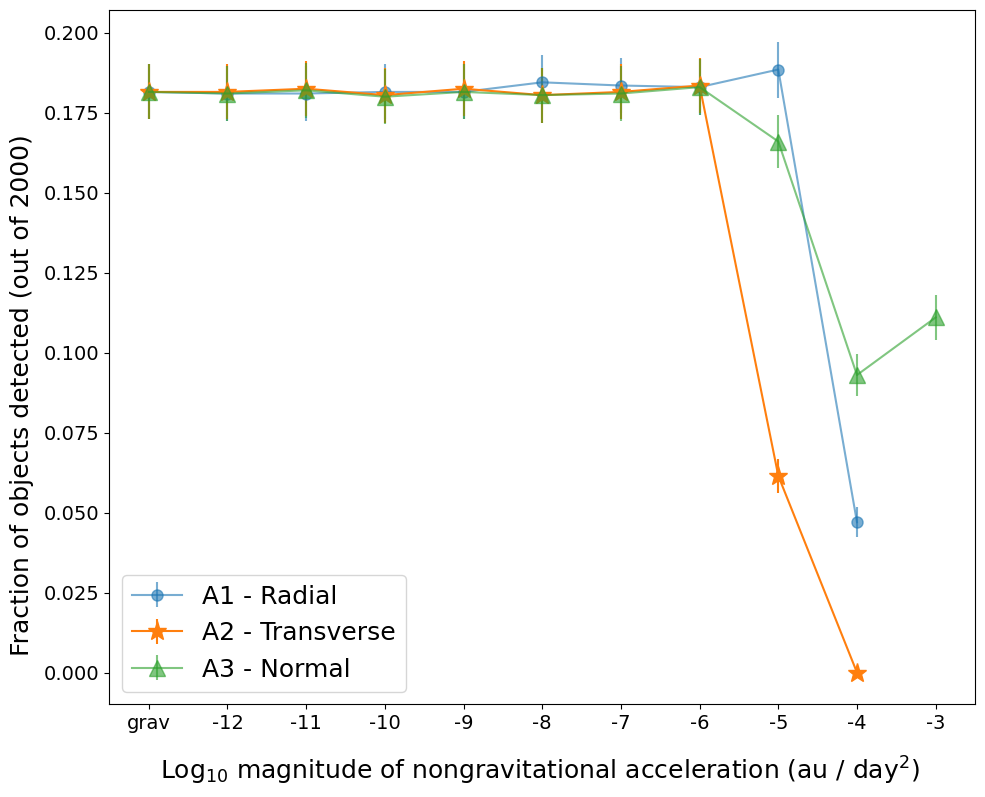

In [62]:
## create the 2-d array of the number of source detections corresponding to 
## each A1 magnitude, then sort on the NGA value

a1 = np.column_stack((np.array(a1_nongrav), np.array(a1_counts)))
sorted_idx = a1[:,0].argsort()
sorted_a1 = a1[sorted_idx]
sorted_a1 = np.concatenate((np.array([[0.0, grav_counts]]), sorted_a1))

ax_labels1 = sorted_a1[:,0].tolist()
ax_labels1 = [int(element1) for element1 in ax_labels1]
ax_labels1[0] = 'grav'
ax_labels1 = [str(element1) for element1 in ax_labels1]

## compute binomial uncertainties to use for error bars
n = 2000
a1_det_sigma = []

for i1 in range(len(sorted_a1)):
    # add in logic to compute error bars
    #print(sorted_a1[i1][1])
    p = sorted_a1[i1][1]/n
    a1_det_sigma.append(float(np.sqrt((p*(1-p))/n)))

print(sorted_a1[:,1]/2000)
print(a1_det_sigma)

a2 = np.column_stack((np.array(a2_nongrav), np.array(a2_counts)))
sorted_idx = a2[:,0].argsort()
sorted_a2 = a2[sorted_idx]
sorted_a2 = np.concatenate((np.array([[0.0, grav_counts]]), sorted_a2))
ax_labels2 = sorted_a2[:,0].tolist()

## add zeros for any NGAs where Sorcha did not make detections
for i in range(len(ax_labels1)):
    if 0<= i < len(ax_labels2):
        continue
    else:
        sorted_a2 = np.insert(sorted_a2, len(sorted_a2), [ax_labels1[i], 0], axis=0) #(np.array([[ax_labels1[i], 0]]), sorted_a2)) 

## compute binomial uncertainties to use for error bars
a2_det_sigma = []

for i2 in range(len(sorted_a2)):
    # add in logic to compute error bars
    #print(sorted_a1[i1][1])
    p = sorted_a2[i2][1]/n
    a2_det_sigma.append(float(np.sqrt((p*(1-p))/n)))

ax_labels2 = sorted_a2[:,0].tolist()
ax_labels2 = [int(element2) for element2 in ax_labels2]
ax_labels2[0] = 'grav'
ax_labels2 = [str(element2) for element2 in ax_labels2]
print(sorted_a2[:,1]/2000)

a3 = np.column_stack((np.array(a3_nongrav), np.array(a3_counts)))
sorted_idx = a3[:,0].argsort()
sorted_a3 = a3[sorted_idx]
sorted_a3 = np.concatenate((np.array([[0.0, grav_counts]]), sorted_a3))

## compute binomial uncertainties to use for error bars
a3_det_sigma = []

for i3 in range(len(sorted_a3)):
    # add in logic to compute error bars
    #print(sorted_a1[i1][1])
    p = sorted_a3[i3][1]/n
    a3_det_sigma.append(float(np.sqrt((p*(1-p))/n)))

ax_labels3 = sorted_a3[:,0].tolist()
ax_labels3 = [int(element3) for element3 in ax_labels3]
ax_labels3[0] = 'grav'
ax_labels3 = [str(element3) for element3 in ax_labels3]
print(sorted_a3[:,1]/2000)

## create table output

for j in range(len(sorted_a3)):

    if j < len(sorted_a1):
        a1_frac = sorted_a1[j,1]/n
    else:
        a1_frac = 0
        a1_det_sigma.append(0.0)

    if j < len(sorted_a2):
        a2_frac = sorted_a2[j,1]/n
    else:
        a2_frac = 0
        a2_det_sigma.append(0.0)

    if j < len(sorted_a3):
        a3_frac = sorted_a3[j,1]/n
    else:
        a3_frac = 0
        a3_det_sigma.append(0.0)
        
    print(f'        $10^{{{ax_labels3[j]}}}$ & {a1_frac:.4g} & {a1_det_sigma[j]:.4g} & {a2_frac:.4g} & {a2_det_sigma[j]:.4g} & {a3_frac:.4g} & {a3_det_sigma[j]:.4g} \\\\')

fig, ax = plt.subplots(figsize=(8,6))
ax.errorbar(x=ax_labels1, y=sorted_a1[:,1]/2000, yerr=a1_det_sigma[:len(ax_labels1)], fmt='o-', label='A1 - Radial', \
            markersize=8, alpha=0.6)
ax.errorbar(x=ax_labels2, y=sorted_a2[:,1]/2000, yerr=a2_det_sigma[:len(ax_labels2)], label='A2 - Transverse', \
            fmt='*-', markersize=14)
ax.errorbar(x=ax_labels3, y=sorted_a3[:,1]/2000, yerr=a3_det_sigma, label='A3 - Normal', fmt='^-', \
            markersize=12, alpha=0.6)
ax.legend(loc='lower left', fontsize=18)
ax.tick_params(axis='both', labelsize=14) 

fig.supylabel('Fraction of objects detected (out of 2000)', fontsize=18)
fig.supxlabel('Log$_{10}$ magnitude of nongravitational acceleration (au / day$^2$)', x=0.55, fontsize=18)

fig.set_figwidth(10)
fig.set_figheight(8)
plt.tight_layout()
plt.savefig('sorcha_detections_2000obj.png', dpi=300)
plt.show()

In [36]:
## run make_tracklets

for k in range(len(out_fnames)):

    print(f'{ofnames[k]}\t{out_fnames[k]}')

    if False: #os.path.isfile(f'{sfpath}pairdets_{ofnames[k]}.csv'):
        continue
    else:
        subprocess.run(['make_tracklets', '-dets', out_fnames[k], '-earth', earth1day_path, \
                        '-obscode', obscodes_path, '-colformat', colformat_path,'-outimgs', \
                        '{0}outim_{1}.txt'.format(sfpath, ofnames[k]), \
                        '-pairdets', '{0}pairdets_{1}.csv'.format(sfpath, ofnames[k]),\
                        '-tracklets', '{0}tracklets_{1}.csv'.format(sfpath, ofnames[k]), \
                        '-trk2det', '{0}trk2det_{1}.csv'.format(sfpath, ofnames[k])], \
                        stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    print(f'make_tracklets has been run on {ofnames[k]}')

fantastic_cart	/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/fantastic_cart_30days_cmi.csv
make_tracklets has been run on fantastic_cart
fantastic_ng_a1_-12.0	/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/fantastic_ng_a1_-12.0_30days_cmi.csv
make_tracklets has been run on fantastic_ng_a1_-12.0
fantastic_ng_a2_-12.0	/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/fantastic_ng_a2_-12.0_30days_cmi.csv
make_tracklets has been run on fantastic_ng_a2_-12.0
fantastic_ng_a3_-12.0	/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/fantastic_ng_a3_-12.0_30days_cmi.csv
make_tracklets has been run on fantastic_ng_a3_-12.0
fantastic_ng_a1_-11.0	/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/fantastic_ng_a1_-11.0_30days_cmi.csv
make_tracklets has been run on fantastic_ng_a1_-11.0
fantastic_ng_a2_-11.0	/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/fantast

In [37]:
## run heliolinx

for l in range(len(ofnames)):

    subprocess.run(['heliolinc', '-imgs', '{0}outim_{1}.txt'.format(sfpath, ofnames[l]), \
                    '-pairdets', '{0}pairdets_{1}.csv'.format(sfpath, ofnames[l]), \
                    '-tracklets', '{0}tracklets_{1}.csv'.format(sfpath, ofnames[l]), \
                    '-trk2det', '{0}trk2det_{1}.csv'.format(sfpath, ofnames[l]), \
                    '-obspos', earth1day_path, '-heliodist', hypo_path, '-outsum',\
                    '{0}sum_{1}.csv'.format(sfpath, ofnames[l]), '-clust2det', \
                    '{0}clust2det_{1}.csv'.format(sfpath, ofnames[l])])

Checking out argv[1] = -imgs.
Checking out argv[3] = -pairdets.
Checking out argv[5] = -tracklets.
Checking out argv[7] = -trk2det.
Checking out argv[9] = -obspos.
Checking out argv[11] = -heliodist.
Checking out argv[13] = -outsum.
Checking out argv[15] = -clust2det.
input image file /home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/outim_fantastic_cart.txt
input detection file /home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/pairdets_fantastic_cart.csv
input tracklet file /home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/tracklets_fantastic_cart.csv
input trk2det file /home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/trk2det_fantastic_cart.csv
input observer position file /home/ellie/research/lsst/heliolinc_files/Earth1day2020s_02a.csv
input heliocentric hypothesis file /home/ellie/research/lsst/sorcha_output/127005pratchett_new/hihyp00b_mb.txt
input reference MJD 0
Defaulting to cluster radius =

In [38]:
## run link_purify -- first, create the lflist file

for m in range(len(ofnames)):
    with open('{0}{1}_lflist'.format(sfpath, ofnames[m]), 'w') as f:
        f.write("{0}sum_{1}.csv {0}clust2det_{1}.csv".format(sfpath, ofnames[m]))
        f.close()

        ## now, actually run link_purify
        subprocess.run(['link_purify','-imgs','{0}outim_{1}.txt'.format(sfpath, ofnames[m]),\
                        '-pairdets','{0}pairdets_{1}.csv'.format(sfpath, ofnames[m]), \
                        '-lflist','{0}{1}_lflist'.format(sfpath, ofnames[m]),\
                        '-outsum','{0}LPLsum_{1}.csv'.format(sfpath, ofnames[m]),\
                        '-clust2det','{0}LPLclust2det_{1}.csv'.format(sfpath, ofnames[m])])

Checking out argv[1] = -imgs.
Checking out argv[3] = -pairdets.
Checking out argv[5] = -lflist.
Checking out argv[7] = -outsum.
Checking out argv[9] = -clust2det.
input paired detection file /home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/pairdets_fantastic_cart.csv
input cluster list file /home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/fantastic_cart_lflist
Maximum RMS in km: 100000
Maximum astrometric RMS: 1
Maximum fraction of points to be rejected: 0.5
Minimum number of observing nights: 3
Minimum number of unique detections: 6
output cluster file /home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/LPLclust2det_fantastic_cart.csv
output rms file /home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/LPLsum_fantastic_cart.csv
Reference MJD will be set to MJD-at-the-epoch from a previous orbit fit, if available.
Defaulting to simplex type = 1
Maximum fraction of points that can be rejected = 0.5, whi

In [39]:
## how many linkages?

links = []
link_filenames = []

for n in range(len(ofnames)):

    if os.path.isfile('{0}LPLsum_{1}.csv'.format(sfpath, ofnames[n])):
        df_links = pd.read_csv('{0}LPLsum_{1}.csv'.format(sfpath, ofnames[n]))
        num_links = len(df_links)

        print(ofnames[n]+' - '+str(num_links))
        #plt.scatter(df_links['orbit_a'], df_links['orbit_e'], marker='.')
        links.append(num_links)
        link_filenames.append(ofnames[n])
    else:
        print('{0}LPLsum_{1}.csv does not exist'.format(sfpath, ofnames[n]))


fantastic_cart - 281
fantastic_ng_a1_-12.0 - 279
fantastic_ng_a2_-12.0 - 285
fantastic_ng_a3_-12.0 - 286
fantastic_ng_a1_-11.0 - 284
fantastic_ng_a2_-11.0 - 283
fantastic_ng_a3_-11.0 - 288
fantastic_ng_a1_-10.0 - 287
fantastic_ng_a2_-10.0 - 285
fantastic_ng_a3_-10.0 - 284
fantastic_ng_a1_-9.0 - 280
fantastic_ng_a2_-9.0 - 286
fantastic_ng_a3_-9.0 - 282
fantastic_ng_a1_-8.0 - 288
fantastic_ng_a2_-8.0 - 289
fantastic_ng_a3_-8.0 - 284
fantastic_ng_a1_-7.0 - 290
fantastic_ng_a2_-7.0 - 292
fantastic_ng_a3_-7.0 - 289
fantastic_ng_a1_-6.0 - 286
fantastic_ng_a2_-6.0 - 303
fantastic_ng_a3_-6.0 - 334
fantastic_ng_a1_-5.0 - 305
fantastic_ng_a2_-5.0 - 76
fantastic_ng_a3_-5.0 - 386
fantastic_ng_a1_-4.0 - 62
fantastic_ng_a3_-4.0 - 252
fantastic_ng_a3_-3.0 - 125


In [40]:
a1_links = []
a1_ngas = []

a2_links = []
a2_ngas = []

a3_links = []
a3_ngas = []

for l in range(len(link_filenames)): 

    if 'a1' in link_filenames[l]:
        a1_links.append(links[l])
        #print(ofnames[l].split('_')[-1])
        a1_ngas.append(float(link_filenames[l].split('_')[-1]))
        print('a1: '+link_filenames[l])

    elif 'a2' in link_filenames[l]:
        a2_links.append(links[l])
        #print(ofnames[l].split('_')[-1])
        a2_ngas.append(float(link_filenames[l].split('_')[-1]))
        print('a2: '+link_filenames[l])
        
    elif 'a3' in link_filenames[l]:
        a3_links.append(links[l])
        #print(ofnames[l].split('_')[-1])
        a3_ngas.append(float(link_filenames[l].split('_')[-1]))
        print('a3: '+link_filenames[l])
        
    else:
        print('saving gravity-only')
        print(link_filenames[l])
        grav_links = links[l]
        print('saved grav only')

saving gravity-only
fantastic_cart
saved grav only
a1: fantastic_ng_a1_-12.0
a2: fantastic_ng_a2_-12.0
a3: fantastic_ng_a3_-12.0
a1: fantastic_ng_a1_-11.0
a2: fantastic_ng_a2_-11.0
a3: fantastic_ng_a3_-11.0
a1: fantastic_ng_a1_-10.0
a2: fantastic_ng_a2_-10.0
a3: fantastic_ng_a3_-10.0
a1: fantastic_ng_a1_-9.0
a2: fantastic_ng_a2_-9.0
a3: fantastic_ng_a3_-9.0
a1: fantastic_ng_a1_-8.0
a2: fantastic_ng_a2_-8.0
a3: fantastic_ng_a3_-8.0
a1: fantastic_ng_a1_-7.0
a2: fantastic_ng_a2_-7.0
a3: fantastic_ng_a3_-7.0
a1: fantastic_ng_a1_-6.0
a2: fantastic_ng_a2_-6.0
a3: fantastic_ng_a3_-6.0
a1: fantastic_ng_a1_-5.0
a2: fantastic_ng_a2_-5.0
a3: fantastic_ng_a3_-5.0
a1: fantastic_ng_a1_-4.0
a3: fantastic_ng_a3_-4.0
a3: fantastic_ng_a3_-3.0


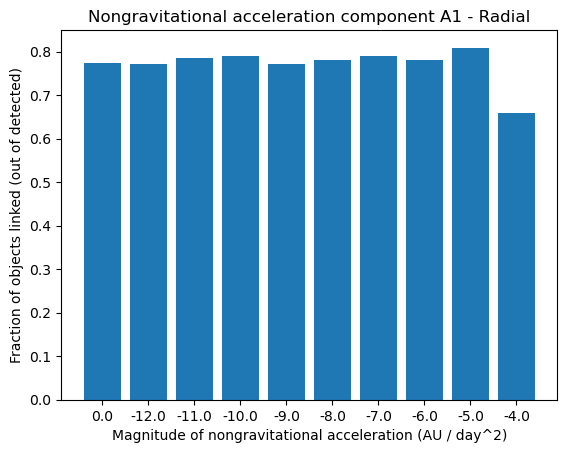

In [41]:
a1_l = np.column_stack((np.array(a1_ngas), np.array(a1_links)))
sorted_idx_l = a1_l[:,0].argsort()
sorted_a1_l = a1_l[sorted_idx_l]
sorted_a1_l = np.concatenate((np.array([[0.0, grav_links]]), sorted_a1_l))


a1_link_fraction = []
for k in range(len(sorted_a1_l)):
    a1_link_fraction.append(sorted_a1_l[:,1][k]/sorted_a1[:,1][k])

plt.bar(sorted_a1_l[:,0].astype(str), a1_link_fraction) #sorted_a1_l[:,1]/sorted_a1[:,1])
#plt.ylim(1570,1600)
#plt.ylim(0.75, 0.79)
plt.ylabel('Fraction of objects linked (out of detected)')
plt.xlabel('Magnitude of nongravitational acceleration (AU / day^2)')
plt.title('Nongravitational acceleration component A1 - Radial')
plt.savefig('linkage_hist_a1.png')
plt.show()

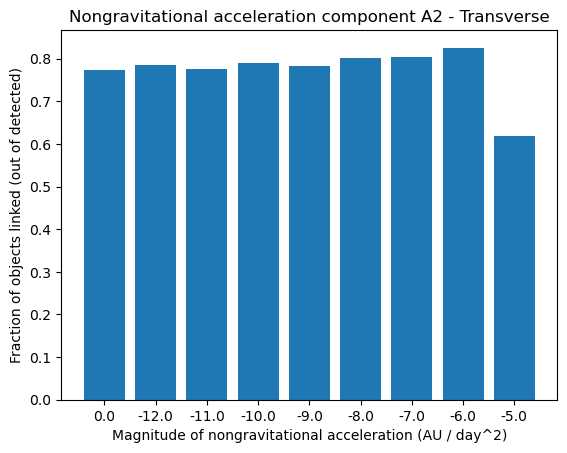

In [42]:
a2_l = np.column_stack((np.array(a2_ngas), np.array(a2_links)))
sorted_idx_l = a2_l[:,0].argsort()
sorted_a2_l = a2_l[sorted_idx_l]
sorted_a2_l = np.concatenate((np.array([[0.0, grav_links]]), sorted_a2_l))


a2_link_fraction = []
for m in range(len(sorted_a2_l)):
    a2_link_fraction.append(sorted_a2_l[:,1][m]/sorted_a2[:,1][m])

plt.bar(sorted_a2_l[:,0].astype(str), a2_link_fraction)
#plt.ylim(1570,1600)
#plt.ylim(0.75, 0.82)
plt.ylabel('Fraction of objects linked (out of detected)')
plt.xlabel('Magnitude of nongravitational acceleration (AU / day^2)')
plt.title('Nongravitational acceleration component A2 - Transverse')
plt.savefig('linkage_hist_a2.png')
plt.show()

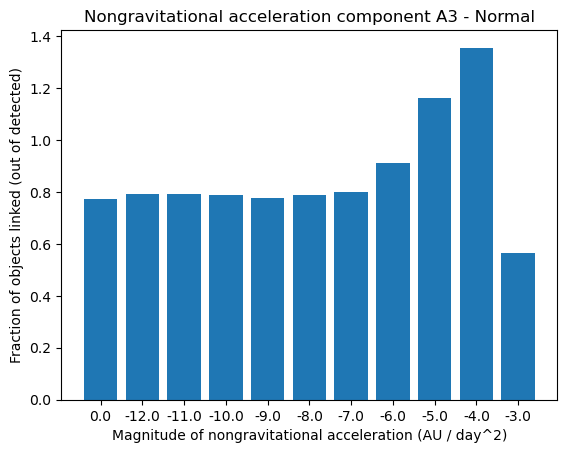

In [43]:
a3_l = np.column_stack((np.array(a3_ngas), np.array(a3_links)))
sorted_idx_l = a3_l[:,0].argsort()
sorted_a3_l = a3_l[sorted_idx_l]
sorted_a3_l = np.concatenate((np.array([[0.0, grav_links]]), sorted_a3_l))


a3_link_fraction = []
for m in range(len(sorted_a3_l)):
    a3_link_fraction.append(sorted_a3_l[:,1][m]/sorted_a3[:,1][m])

plt.bar(sorted_a3_l[:,0].astype(str), a3_link_fraction)
#plt.ylim(1570,1600)
#plt.ylim(0.75, 0.92)
plt.ylabel('Fraction of objects linked (out of detected)')
plt.xlabel('Magnitude of nongravitational acceleration (AU / day^2)')
plt.title('Nongravitational acceleration component A3 - Normal')
plt.savefig('linkage_hist_a3.png')
plt.show()

In [79]:
ngas = ['cart', -12.0, -11.0, -10.0, -9.0, -8.0, -7.0, -6.0, -5.0, -4.0, -3.0] #, -2.0, -1.0, 0.0, 1.0] 
parse_fnames = []

for n in ngas:

    #if os.path.isfile(f'{sfpath}LPLsum_{1}.csv'.format(sfpath, ofnames[n]))

    if n == 'cart':
        pairdet = f"{sfpath}pairdets_{fname_stem}_{str(n)}.csv"
        insum = f"{sfpath}LPLsum_{fname_stem}_{str(n)}.csv"
        clust2det = f"{sfpath}LPLclust2det_{fname_stem}_{str(n)}.csv"
        outfile = f"{sfpath}parse_clust2det_{str(n)}.csv"

        subprocess.run(['parse_clust2det','-pairdet',pairdet,'-insum', insum, '-clust2det', clust2det, '-out', outfile])
        parse_fnames.append(outfile)
        continue
    
    ## for a1
    pairdet_a1 = f"{sfpath}pairdets_{fname_stem}_ng_a1_{str(n)}.csv"
    insum_a1 = f"{sfpath}LPLsum_{fname_stem}_ng_a1_{str(n)}.csv"
    clust2det_a1 = f"{sfpath}LPLclust2det_{fname_stem}_ng_a1_{str(n)}.csv"
    outfile_a1 = f"{sfpath}parse_clust2det_a1_{str(n)}.csv"

    subprocess.run(['parse_clust2det','-pairdet',pairdet_a1,'-insum', insum_a1, '-clust2det', clust2det_a1, '-out', outfile_a1])

    ## for a2
    pairdet_a2 = f"{sfpath}pairdets_{fname_stem}_ng_a2_{str(n)}.csv"
    insum_a2 = f"{sfpath}LPLsum_{fname_stem}_ng_a2_{str(n)}.csv"
    clust2det_a2 = f"{sfpath}LPLclust2det_{fname_stem}_ng_a2_{str(n)}.csv"
    outfile_a2 = f"{sfpath}parse_clust2det_a2_{str(n)}.csv"

    subprocess.run(['parse_clust2det','-pairdet',pairdet_a2,'-insum', insum_a2, '-clust2det', clust2det_a2, '-out', outfile_a2])

    ## for a3
    pairdet_a3 = f"{sfpath}pairdets_{fname_stem}_ng_a3_{str(n)}.csv"
    insum_a3 = f"{sfpath}LPLsum_{fname_stem}_ng_a3_{str(n)}.csv"
    clust2det_a3 = f"{sfpath}LPLclust2det_{fname_stem}_ng_a3_{str(n)}.csv"
    outfile_a3 = f"{sfpath}parse_clust2det_a3_{str(n)}.csv"

    subprocess.run(['parse_clust2det','-pairdet',pairdet_a3,'-insum', insum_a3, '-clust2det', clust2det_a3, '-out', outfile_a3])

    parse_fnames.append(outfile_a1)
    parse_fnames.append(outfile_a2)
    parse_fnames.append(outfile_a3)

Checking out argv[1] = -pairdet.
Checking out argv[3] = -insum.
Checking out argv[5] = -clust2det.
Checking out argv[7] = -out.
input paired detection file /home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/pairdets_fantastic_cart.csv
input cluster summary file /home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/LPLsum_fantastic_cart.csv
input cluster-to-detection file /home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/LPLclust2det_fantastic_cart.csv
output file /home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/parse_clust2det_cart.csv
Read 6018 data lines from paired detection file /home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/pairdets_fantastic_cart.csv
Read 281 data lines from cluster summary file /home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/LPLsum_fantastic_cart.csv
Read 5459 data lines from cluster-to-detection file /home/ellie/research/lsst/sorc

can't open input file /home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/pairdets_fantastic_ng_a2_-4.0.csv
ERROR: could not successfully read paired detection file /home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/pairdets_fantastic_ng_a2_-4.0.csv
read_pairdet_file returned status = 1.
can't open input file /home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/pairdets_fantastic_ng_a1_-3.0.csv
ERROR: could not successfully read paired detection file /home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/pairdets_fantastic_ng_a1_-3.0.csv
read_pairdet_file returned status = 1.
can't open input file /home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/pairdets_fantastic_ng_a2_-3.0.csv
ERROR: could not successfully read paired detection file /home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/pairdets_fantastic_ng_a2_-3.0.csv
read_pairdet_file returned status = 1.


10 points found for cluster 25
Parameters of along-track fit: 344.254 0.135469 -0.00208564
Parameters of cross-track fit: 0.00548919 -0.00222669 -0.00220143
10 points found for cluster 26
Parameters of along-track fit: 320.894 0.101682 0.000287987
Parameters of cross-track fit: 0.00264239 0.0018859 -0.00263368
8 points found for cluster 27
Parameters of along-track fit: 349.351 0.115453 -0.00160344
Parameters of cross-track fit: 0.0179273 0.0015396 -0.00272435
20 points found for cluster 28
Parameters of along-track fit: 345.061 0.0300923 -0.00195212
Parameters of cross-track fit: 0.0052345 0.00377611 -0.00202272
9 points found for cluster 29
Parameters of along-track fit: 331.227 0.189785 -0.000638312
Parameters of cross-track fit: 0.00462939 0.000515793 -0.00338821
12 points found for cluster 30
Parameters of along-track fit: 166.283 0.183901 0.000770597
Parameters of cross-track fit: -0.00626628 0.000335508 0.0038899
8 points found for cluster 31
Parameters of along-track fit: 182.3

In [97]:
a1_filtered_links = []
a1_all_links = []
a1_ngas = []
a1_false_links = []
a1_false_link_rates = []
a1_sig_vals = []
a1_residuals = []

a2_filtered_links = []
a2_all_links = []
a2_ngas = []
a2_false_links = []
a2_false_link_rates = []
a2_sig_vals = []
a2_residuals = []

a3_filtered_links = []
a3_all_links = []
a3_ngas = []
a3_false_links = []
a3_false_link_rates = []
a3_sig_vals = []
a3_residuals = []

for f in parse_fnames:
    print(f)

    if not os.path.isfile(f):
        print(f+' does not exist')
        continue
    
    cols = ['MJD','RA','Dec','mag','trail_len','trail_PA','sigmag','sig_across','sig_along',\
            'image','idstring','band','obscode','known_obj','det_qual','clusternum']
    
    df = pd.read_csv(f, skiprows=3, on_bad_lines='skip', names=cols, comment='#') #'warn')

    ## add another line to read the same file into another df, but just read the single lines above each
    ## cluster so you can get the astromRMS for each cluster, and match the clusternum below
    cols_res = ['clusternum','posRMS','velRMS','totRMS','astromRMS','timespan','uniquepoints','obsnights',\
                'metric','orbit_a','orbit_e','orbit_incl','orbit_MJD','orbitX','orbitY','orbitZ',
                'orbitVX','orbitVY','orbitVZ','orbit_eval_count','avg_det_qual','max_known_obj','minvel',\
                'maxvel','minGCR','maxGCR','minpa','maxpa','mintimespan','maxtimespan','minarc','maxarc',\
                'stringID','min_nightstep','max_nightstep','magmean','magrms','magrange','rating',\
                'crossaccel','alongaccel','totalaccel']

    df_res = pd.read_csv(f, skiprows=1, on_bad_lines='skip', names=cols_res, comment='#')
    #print('***residual df***')
    #print(df_res.head(5))

    ## create a nested list for residuals -- e.g., ai_residuals = [[residuals for -12], [residuals for -11], ...]
    
    #print(df.head())
    
    cluster_nums = df['clusternum'].unique().tolist()
    bad_clusters = []
    #print(urows)

    prev_ids = []

    ## loop through each cluster and check if 
    for cluster in cluster_nums:
        df_cluster = df[df['clusternum'] == cluster]
        df_cluster.reset_index(drop=True, inplace=True) 

        #print(df_cluster['idstring'].nunique())
        
        if df_cluster['idstring'].nunique() == 1:
            ## now check if this id string has appeared in a previous linkage
            if df_cluster['idstring'][0] in prev_ids:
                bad_clusters.append(cluster)
            else:
                prev_ids.append(df_cluster['idstring'][0])
            
        else:
            bad_clusters.append(cluster)

    good_clusters = [item for item in cluster_nums if item not in bad_clusters]

    if 'a1' in f:
        a1_filtered_links.append(len(good_clusters))
        a1_all_links.append(len(cluster_nums))
        a1_ngas.append(f.split('_')[-1][:-4])
        print('in a1')
        print(bad_clusters)

        df_res_cluster = df_res[df_res['clusternum'].isin(good_clusters)]
        #print(df_res_cluster)
        a1_residuals.append(df_res_cluster['astromRMS'].tolist())
        
        a1_false_links.append(len(bad_clusters))
        if len(cluster_nums) != 0:
            a1_false_link_rates.append((len(bad_clusters))/len(cluster_nums))

            n = len(cluster_nums)
            p = len(bad_clusters)/len(cluster_nums)
            a1_sig_vals.append(float(np.sqrt((p*(1-p))/n)))
            
        else:
            a1_false_link_rates.append('undefined')
        
        print(f)
        continue

    if 'a2' in f:
        a2_filtered_links.append(len(good_clusters))
        a2_all_links.append(len(cluster_nums))
        a2_ngas.append(f.split('_')[-1][:-4])
        print('in a2')
        print(bad_clusters)
        
        a2_false_links.append(len(bad_clusters))

        df_res_cluster = df_res[df_res['clusternum'].isin(good_clusters)]
        #print(df_res_cluster)
        a2_residuals.append(df_res_cluster['astromRMS'].tolist())
        
        if len(cluster_nums) != 0:
            a2_false_link_rates.append((len(bad_clusters))/len(cluster_nums))

            n = len(cluster_nums)
            p = len(bad_clusters)/len(cluster_nums)
            a2_sig_vals.append(float(np.sqrt((p*(1-p))/n)))
            
        else:
            a2_false_link_rates.append('undefined')
        
        print(f)
        continue

    if 'a3' in f:
        a3_filtered_links.append(len(good_clusters))
        a3_all_links.append(len(cluster_nums))
        a3_ngas.append(f.split('_')[-1][:-4])
        print('in a3')
        print(bad_clusters)
        
        a3_false_links.append(len(bad_clusters))

        df_res_cluster = df_res[df_res['clusternum'].isin(good_clusters)]
        #print(df_res_cluster)
        a3_residuals.append(df_res_cluster['astromRMS'].tolist())
        
        if len(cluster_nums) != 0:
            a3_false_link_rates.append((len(bad_clusters))/len(cluster_nums))

            n = len(cluster_nums)
            p = len(bad_clusters)/len(cluster_nums)
            a3_sig_vals.append(float(np.sqrt((p*(1-p))/n)))
            
        else:
            a3_false_link_rates.append('undefined')
        
        print(f)
        continue

    else:
        grav_filtered_links = len(good_clusters)
        grav_all_links = len(cluster_nums)
        print('in grav only')
        print(bad_clusters)
        print(f)

print(a1_ngas)
print(a1_false_link_rates)
print()

print(a2_ngas)
print(a2_false_link_rates)
print()

print(a3_ngas)
print(a3_false_link_rates)
print()

for j in range(len(a3_ngas)):
    if j < len(a1_ngas):
        a1_false = a1_false_link_rates[j]
        a1_sig = a1_sig_vals[j]
    else:
        a1_false = 0.999
        a1_sig = 0.999
        
    if j < len(a2_ngas):
        a2_false = a2_false_link_rates[j]
        a2_sig = a2_sig_vals[j]
    else:
        a2_false = 0.999
        a2_sig = 0.999
        
    if j < len(a3_ngas):
        a3_false = a3_false_link_rates[j]
        a3_sig = a3_sig_vals[j]
    else:
        a3_false = 0.999
        a3_sig = 0.999
     
    print(f'        $10^{{{a3_ngas[j]}}}$ & {a1_false:.4g} & {a1_sig:.4g} & {a2_false:.4g} & {a2_sig:.4g} & {a3_false:.4g} & {a3_sig:.4g} \\\\')

#for r in range(len(a3_residuals)):
#    print(len(a3_residuals[r]))   
#    print(a3_filtered_links[r])
#    print()
#print()
#print(len(a2_residuals))

/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/parse_clust2det_cart.csv
in grav only
[]
/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/parse_clust2det_cart.csv
/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/parse_clust2det_a1_-12.0.csv
in a1
[]
/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/parse_clust2det_a1_-12.0.csv
/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/parse_clust2det_a2_-12.0.csv
in a2
[]
/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/parse_clust2det_a2_-12.0.csv
/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/parse_clust2det_a3_-12.0.csv
in a3
[268]
/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/parse_clust2det_a3_-12.0.csv
/home/ellie/research/lsst/sorcha_output/link_fantastic/with_link_filter/parse_clust2det_a1_-11.0.csv
in a1
[]
/home/ellie/research/lsst/sorcha_output/link

0.9992439662692643
1.0062808956091887
1.0105263157894737
1.0035087719298244
0.9940949935815148
1.0029829341746737
0.9674431981593327
1.0304341756247382
0.8942889137737962
-12.0
-11.0
-10.0
-9.0
-8.0
-7.0
-6.0
-5.0
-4.0
sizes:
9
9
9
        $10^{-12.0}$ & 0.9992 & 0.02161 & 1.014 & 0.02114 & 1.003 & 0.02151 \\
        $10^{-11.0}$ & 1.006 & 0.02141 & 1.005 & 0.02136 & 1.004 & 0.02141 \\
        $10^{-10.0}$ & 1.011 & 0.02125 & 1.027 & 0.02081 & 1.008 & 0.0214 \\
        $10^{-9.0}$ & 1.004 & 0.02146 & 1.005 & 0.02136 & 1 & 0.02156 \\
        $10^{-8.0}$ & 0.9941 & 0.02155 & 1.044 & 0.02022 & 1.016 & 0.02114 \\
        $10^{-7.0}$ & 1.003 & 0.02135 & 1.035 & 0.02048 & 1.034 & 0.02053 \\
        $10^{-6.0}$ & 0.9674 & 0.02234 & 1.045 & 0.02005 & 0.9918 & 0.0217 \\
        $10^{-5.0}$ & 1.03 & 0.02024 & 0.6213 & 0.04507 & 1.028 & 0.02165 \\
        $10^{-4.0}$ & 0.8943 & 0.04717 & 0 & 0 & 1.089 & 0.02583 \\
        $10^{-3.0}$ & 0 & 0 & 0 & 0 & 0.5049 & 0.03283 \\


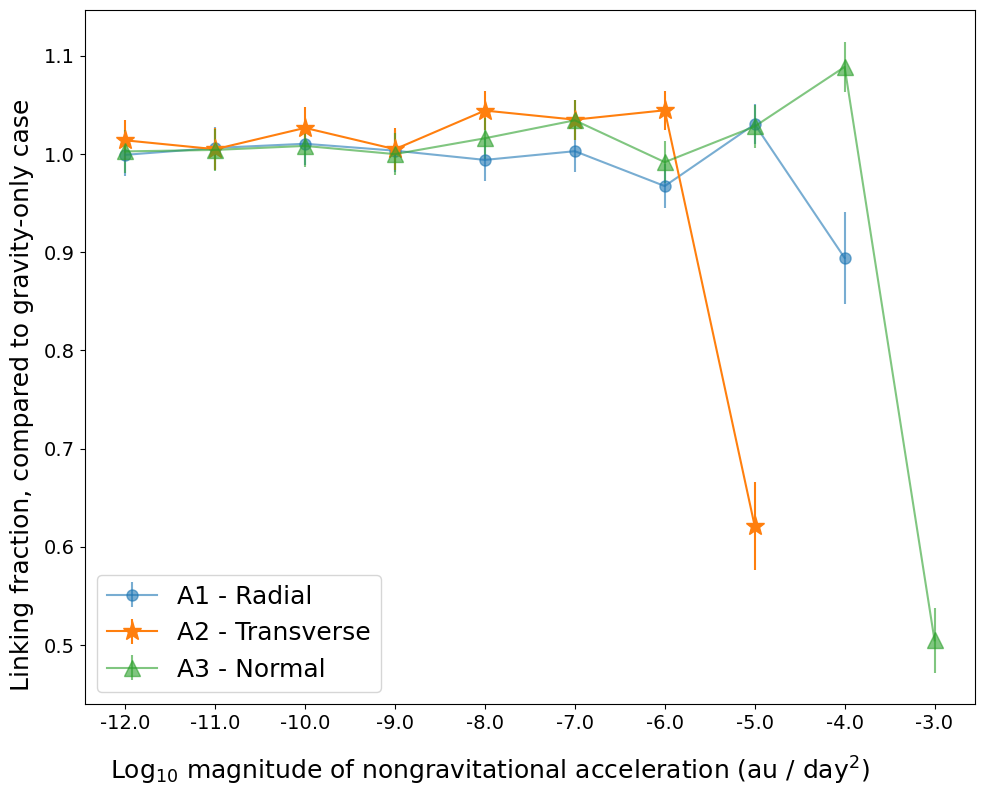

In [70]:
## now, plot the new link histograms: 
#fig, (ax1, ax2, ax3) = plt.subplots(3, 1)

x_vals = np.array(a1_ngas).astype(str).tolist()
#x_vals[0] = 'only grav'

a1_filtered_links_g = [grav_filtered_links]+a1_filtered_links

## compute binomial uncertainties to use for error bars
a1_link_sigma = []

a1_link_fraction = []
for m in range(len(a1_filtered_links_g)):
    if m != 0:
        n = sorted_a1[:,1][m]
        p = a1_filtered_links_g[m]/n
        a1_link_sigma.append(float(np.sqrt((p*(1-p))/n))) 
    
    a1_link_fraction.append(a1_filtered_links_g[m]/sorted_a1[:,1][m])

a1_link_frac_wrt_grav = []
for l in range(len(a1_link_fraction)-1):
    a1_link_frac_wrt_grav.append(a1_link_fraction[l+1]/a1_link_fraction[0])

for a in a1_link_frac_wrt_grav:
    print(a.item())

for x in x_vals:
    print(x)
#print(x_vals[1:])
print('sizes:')

print(len(a1_link_frac_wrt_grav))
print(len(a1_link_sigma))

#ax1.bar(x_vals, a1_link_frac_wrt_grav, label='A1 - Radial')
#ax1.legend(loc='lower right', fontsize=15)

x2_vals = np.array(a2_ngas).astype(str).tolist()
#x_vals[0] = 'only grav'

a2_filtered_links_g = [grav_filtered_links]+a2_filtered_links

a2_link_sigma = []
a2_link_fraction = []

for m in range(len(a2_filtered_links_g)):
    if m != 0:
        n = sorted_a2[:,1][m]
        p = a2_filtered_links_g[m]/n
        a2_link_sigma.append(float(np.sqrt((p*(1-p))/n))) 
    
    a2_link_fraction.append(a2_filtered_links_g[m]/sorted_a2[:,1][m])

a2_link_frac_wrt_grav = []
for l in range(len(a2_link_fraction)-1):
    a2_link_frac_wrt_grav.append(a2_link_fraction[l+1]/a2_link_fraction[0])
    #print(a2_link_fraction[l+1]/a2_link_fraction[0])

'''x_vals = np.insert(x_vals, 8, '-4.0')
a2_link_frac_wrt_grav = np.insert(a2_link_frac_wrt_grav, 8, 0.0)

x_vals = np.insert(x_vals, 9, '-3.0')
a2_link_frac_wrt_grav = np.insert(a2_link_frac_wrt_grav, 9, 0.0)

x_vals = np.insert(x_vals, 10, '-2.0')
a2_link_frac_wrt_grav = np.insert(a2_link_frac_wrt_grav, 10, 0.0)'''

#print(a2_link_frac_wrt_grav)

#ax2.bar(x_vals, a2_link_frac_wrt_grav, label='A2 - Transverse')
#ax2.legend(loc='lower right', fontsize=15)

x3_vals = np.array(a3_ngas).astype(str).tolist()
#x_vals[0] = 'only grav'

a3_filtered_links_g = [grav_filtered_links]+a3_filtered_links

a3_link_fraction = []
a3_link_sigma = []

for m in range(len(a3_filtered_links_g)):
    #print(a3_filtered_links_g[m])
    #print(sorted_a3[:,1][m])
    if m != 0:
        n = sorted_a3[:,1][m]
        p = a3_filtered_links_g[m]/n
        a3_link_sigma.append(float(np.sqrt((p*(1-p))/n))) 
    a3_link_fraction.append(a3_filtered_links_g[m]/sorted_a3[:,1][m])

a3_link_frac_wrt_grav = []
for l in range(len(a3_link_fraction)-1):
    a3_link_frac_wrt_grav.append(a3_link_fraction[l+1]/a3_link_fraction[0])
    #print(a3_link_fraction[l+1]/a3_link_fraction[0])

#print(a3_link_frac_wrt_grav)

print(len(x_vals))

#f = plt.figure()
#f.set_figwidth(8)

for j in range(len(x3_vals)):
    if j < len(a1_link_frac_wrt_grav):
        a1_frac = a1_link_frac_wrt_grav[j]
        a1_sig = a1_link_sigma[j]
    else:
        a1_frac = 0
        a1_sig = 0
    if j < len(a2_link_frac_wrt_grav):
        a2_frac = a2_link_frac_wrt_grav[j]
        a2_sig = a2_link_sigma[j]
    else:
        a2_frac = 0
        a2_sig = 0
    if j < len(a3_link_frac_wrt_grav):
        a3_frac = a3_link_frac_wrt_grav[j]
        a3_sig = a3_link_sigma[j]
    else:
        a3_frac = 0
        a3_sig = 0
     
    print(f'        $10^{{{x3_vals[j]}}}$ & {a1_frac:.4g} & {a1_sig:.4g} & {a2_frac:.4g} & {a2_sig:.4g} & {a3_frac:.4g} & {a3_sig:.4g} \\\\')

fig, ax = plt.subplots(figsize=(8,6))
ax.errorbar(x=x_vals, y=a1_link_frac_wrt_grav, yerr=a1_link_sigma, fmt='o-', label='A1 - Radial', markersize=8, alpha=0.6)
ax.errorbar(x=x2_vals, y=a2_link_frac_wrt_grav, yerr=a2_link_sigma, fmt='*-', label='A2 - Transverse', markersize=14)
ax.errorbar(x=x3_vals, y=a3_link_frac_wrt_grav, yerr=a3_link_sigma, fmt='^-', label='A3 - Normal', markersize=12, alpha=0.6)
ax.legend(loc='lower left', fontsize=18)

ax.tick_params(axis='both', labelsize=14)

#ax3.bar(x_vals, a3_link_frac_wrt_grav, label='A3 - Normal')
#ax3.legend(loc='lower right', fontsize=15)

fig.supylabel('Linking fraction, compared to gravity-only case', fontsize=18)
fig.supxlabel('Log$_{10}$ magnitude of nongravitational acceleration (au / day$^2$)', fontsize=18)

fig.set_figwidth(10)
fig.set_figheight(8)
plt.tight_layout()

plt.savefig('linkage_plot_ai_2000.png', dpi=300)
plt.show()

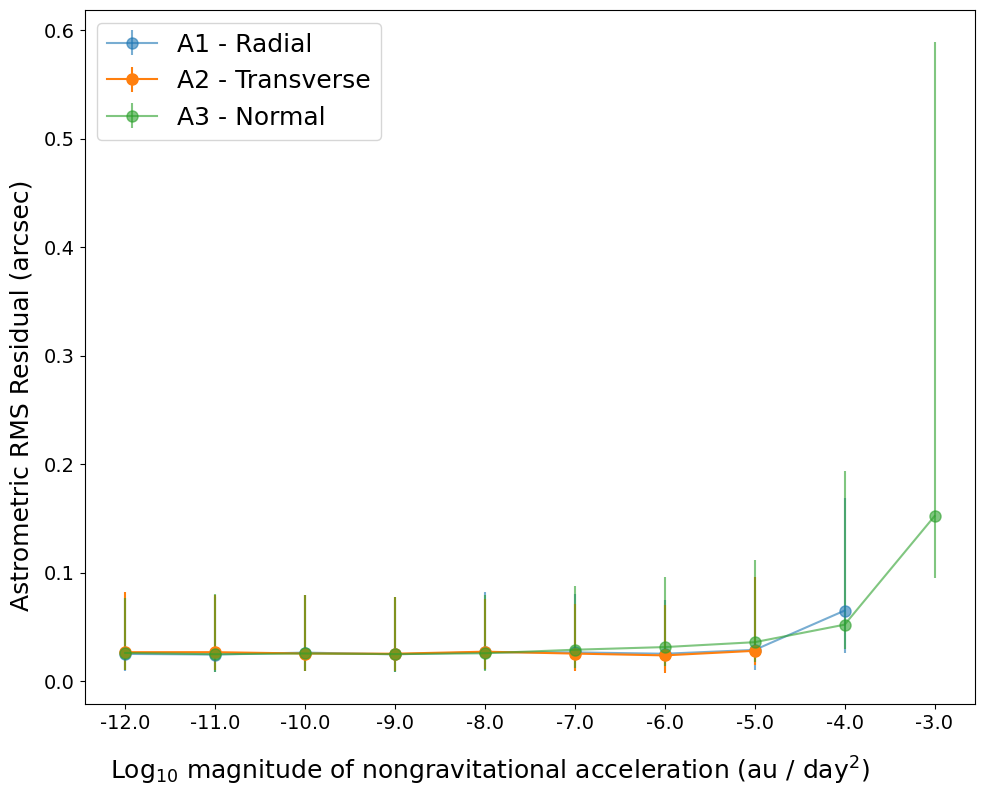

In [109]:
## Make astrometric residual plots, per Matt's request

## first, compute median astrometric RMS for each NGA magnitude, for each Ai
## do A1 first: 

a1_res_med = []
a1_err_low = []
a1_err_high = []

for i in range(len(a1_residuals)):
    a1_res_med.append(np.median(a1_residuals[i]))
    a1_err_low.append(np.percentile(a1_residuals[i], 16))
    a1_err_high.append(np.percentile(a1_residuals[i], 84))

a1_error_matrix = np.vstack([a1_err_low, a1_err_high])
fig, ax = plt.subplots(figsize=(8,6))
ax.errorbar(x=x_vals, y=a1_res_med, yerr=a1_error_matrix, fmt='o-', label='A1 - Radial', markersize=8, alpha=0.6)

a2_res_med = []
a2_err_low = []
a2_err_high = []

for i in range(len(a2_residuals)):
    a2_res_med.append(np.median(a2_residuals[i]))
    a2_err_low.append(np.percentile(a2_residuals[i], 16))
    a2_err_high.append(np.percentile(a2_residuals[i], 84))

a2_error_matrix = np.vstack([a2_err_low, a2_err_high])
ax.errorbar(x=x2_vals, y=a2_res_med, yerr=a2_error_matrix, fmt='o-', label='A2 - Transverse', markersize=8)

a3_res_med = []
a3_err_low = []
a3_err_high = []

for i in range(len(a3_residuals)):
    a3_res_med.append(np.median(a3_residuals[i]))
    a3_err_low.append(np.percentile(a3_residuals[i], 16))
    a3_err_high.append(np.percentile(a3_residuals[i], 84))

a3_error_matrix = np.vstack([a3_err_low, a3_err_high])
ax.errorbar(x=x3_vals, y=a3_res_med, yerr=a3_error_matrix, fmt='o-', label='A3 - Normal', markersize=8, alpha=0.6)

ax.tick_params(axis='both', labelsize=14)

fig.supylabel('Astrometric RMS Residual (arcsec)', fontsize=18)
fig.supxlabel('Log$_{10}$ magnitude of nongravitational acceleration (au / day$^2$)', fontsize=18)

ax.legend(loc='upper left', fontsize=18)

fig.set_figwidth(10)
fig.set_figheight(8)
plt.tight_layout()

plt.savefig('astromRMS_plot_ai_2000.png', dpi=300)
plt.show()

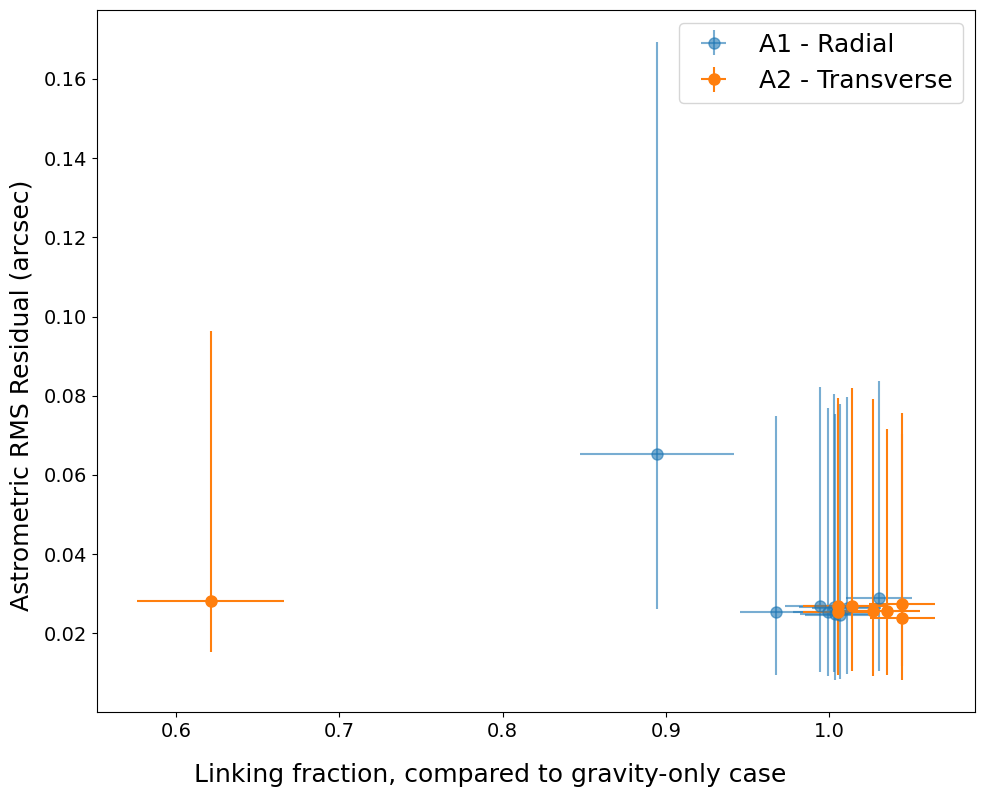

In [114]:
## plot linking ratio against RMS residuals

fig, ax = plt.subplots(figsize=(8,6))
ax.errorbar(x=a1_link_frac_wrt_grav, y=a1_res_med, xerr=a1_link_sigma, yerr=a1_error_matrix, fmt='o', label='A1 - Radial', markersize=8, alpha=0.6)
ax.errorbar(x=a2_link_frac_wrt_grav, y=a2_res_med, xerr=a2_link_sigma, yerr=a2_error_matrix, fmt='o', label='A2 - Transverse', markersize=8)
ax.errorbar(x=a3_link_frac_wrt_grav, y=a3_res_med, xerr=a3_link_sigma, yerr=a3_error_matrix, fmt='o', label='A3 - Normal', markersize=8, alpha=0.6)

ax.tick_params(axis='both', labelsize=14)

fig.supylabel('Astrometric RMS Residual (arcsec)', fontsize=18)
fig.supxlabel('Linking fraction, compared to gravity-only case', fontsize=18)

ax.legend(loc='upper right', fontsize=18)

fig.set_figwidth(10)
fig.set_figheight(8)
plt.tight_layout()

plt.savefig('astromRMS_linkfrac_plot_ai_2000.png', dpi=300)
plt.show()